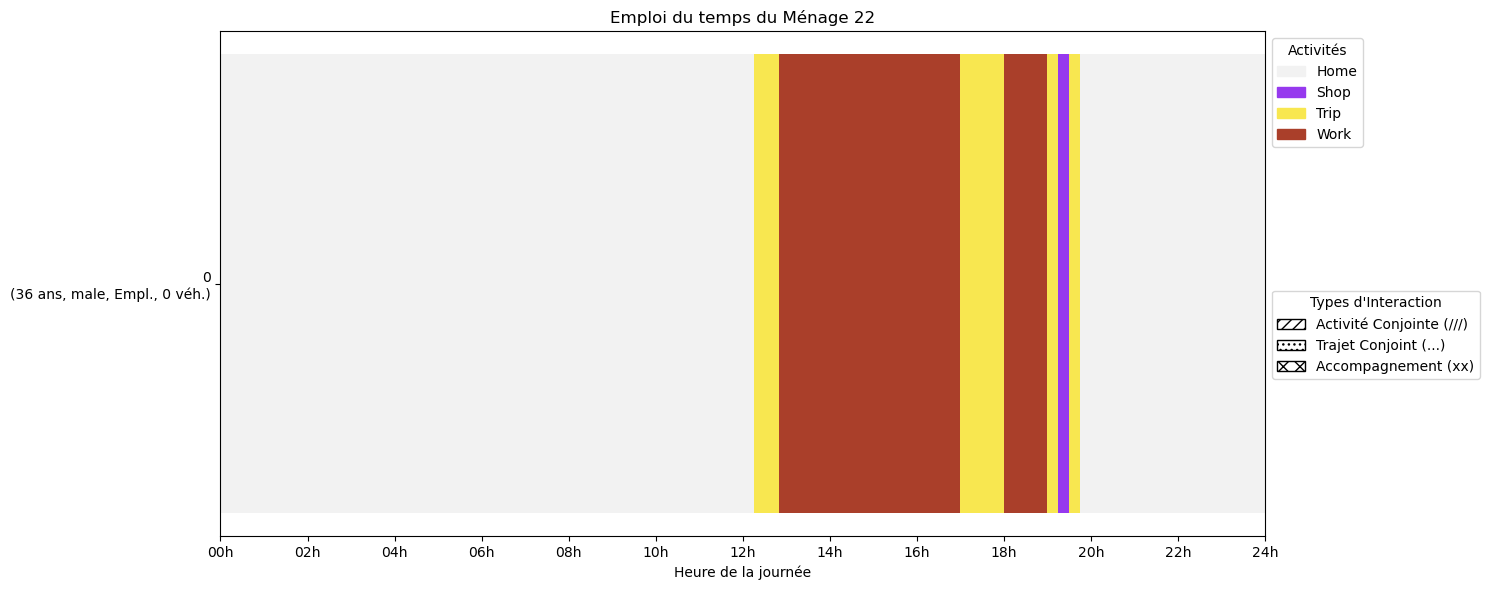

,schedule_id,pid,start_h,end_h,act,interaction_type
0,0,0,00:00,12:15,home,0
1,1,0,12:15,12:50,trip,0
2,2,0,12:50,17:00,work,0
3,3,0,17:00,18:00,trip,0
4,4,0,18:00,19:00,work,0
5,5,0,19:00,19:15,trip,0
6,6,0,19:15,19:30,shop,0
7,7,0,19:30,19:45,trip,0
8,8,0,19:45,24:00,home,0


In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

ACTIVITY_COLORS = {
    'home': '#f2f2f2',      
    'work': "#AA3F2A",      
    'shop': "#9639ee",      
    'education': '#1f77b4', 
    'leisure': '#2ca02c',   
    'escort': '#ff7f0e',    
    'other': '#d62728',     
    'trip': "#f8e750",      
    'unknown': '#333333'   
}

def plot_household_interaction_gantt(
    hid, 
    df_schedules, 
    df_interactions, 
    df_attributes=None,
    figsize=(15, 6),
    return_trips_df=True
):
    household_data = df_schedules[df_schedules['hid'] == hid].copy()

    if 'schedule_id' in household_data.columns and 'schedule_id' in df_interactions.columns:
        interactions_subset = df_interactions[['schedule_id', 'interaction_type']]
        household_data = household_data.merge(interactions_subset, on='schedule_id', how='left')
        household_data['interaction_type'] = household_data['interaction_type'].fillna(0).astype(int)
    else:
        print("Attention: Pas de colonne 'schedule_id' pour joindre les interactions.")
        household_data['interaction_type'] = 0

    # tri lisible
    household_trips = household_data.sort_values(['pid', 'start', 'end'])

    # convertir minutes -> format heure pour lecture
    def min_to_hhmm(m):
        h = int(m) // 60
        mm = int(m) % 60
        return f"{h:02d}:{mm:02d}"

    household_trips['start_h'] = household_trips['start'].apply(min_to_hhmm)
    household_trips['end_h'] = household_trips['end'].apply(min_to_hhmm)
    household_trips['duration_min'] = household_trips['end'] - household_trips['start']

    # garder colonnes utiles
    keep_cols = ['schedule_id','pid','start_h','end_h','act','interaction_type']
    keep_cols = [c for c in keep_cols if c in household_trips.columns]
    household_trips = household_trips[keep_cols]

    # ---- le reste de ton code de plot (inchangé) ----
    interaction_styles = {
        0: {'hatch': '', 'edgecolor': 'none', 'label': 'Seul'},
        1: {'hatch': '///', 'edgecolor': 'black', 'label': 'Activité Conjointe (///)'}, 
        2: {'hatch': '...', 'edgecolor': 'black', 'label': 'Trajet Conjoint (...)'},
        3: {'hatch': 'xx', 'edgecolor': 'black', 'label': 'Accompagnement (xx)'}
    }

    fig, ax = plt.subplots(figsize=figsize)

    members = sorted(household_data['pid'].unique())
    y_mapping = {pid: i for i, pid in enumerate(members)}
    bar_height = 0.8

    present_acts = set()

    for _, row in household_data.iterrows():
        y = y_mapping[row['pid']]
        start = row['start']
        duration = row['end'] - row['start']

        raw_act = str(row['act'])
        act_key = raw_act.lower().strip()
        present_acts.add(act_key)

        color = ACTIVITY_COLORS.get(act_key, ACTIVITY_COLORS['unknown'])

        itype = row['interaction_type']
        style = interaction_styles.get(itype, interaction_styles[0])

        ax.barh(
            y=y,
            width=duration,
            left=start,
            height=bar_height,
            color=color,
            edgecolor=style['edgecolor'],
            hatch=style['hatch'],
            linewidth=0.5 if itype == 0 else 1.5,
            align='center'
        )

    ax.set_yticks(list(y_mapping.values()))

    y_labels = []
    for pid in members:
        label = f"PID: {pid}"
        if df_attributes is not None:
            attr = df_attributes[df_attributes['pid'] == pid]
            if not attr.empty:
                age = attr.iloc[0].get('age', '?')
                sex = attr.iloc[0].get('sex', '?')
                employed = attr.iloc[0].get('employed', '?')
                vehicles = attr.iloc[0].get('number_of_vehicles', '?')
                label = f"{pid}\n({age} ans, {sex}, {'Empl.' if employed else 'Chôm.'}, {vehicles} véh.)"
        y_labels.append(label)

    ax.set_yticklabels(y_labels)

    ax.set_xlim(0, 1440)
    ax.set_xticks(np.arange(0, 1441, 120))
    ax.set_xticklabels([f"{int(h//60):02d}h" for h in np.arange(0, 1441, 120)])
    ax.set_xlabel("Heure de la journée")
    ax.set_title(f"Emploi du temps du Ménage {hid}")

    sorted_acts = sorted(list(present_acts))
    act_patches = []
    for act in sorted_acts:
        c = ACTIVITY_COLORS.get(act, ACTIVITY_COLORS['unknown'])
        act_patches.append(mpatches.Patch(color=c, label=act.capitalize()))

    legend1 = ax.legend(handles=act_patches, title="Activités", loc='upper left', bbox_to_anchor=(1, 1))

    int_patches = []
    for itype, style in interaction_styles.items():
        if itype == 0:
            continue
        int_patches.append(mpatches.Patch(facecolor='white', edgecolor='black', hatch=style['hatch'], label=style['label']))

    if int_patches:
        ax.legend(handles=int_patches, title="Types d'Interaction", loc='upper left', bbox_to_anchor=(1, 0.5))
        ax.add_artist(legend1)

    plt.tight_layout()
    plt.show()

    if return_trips_df:
        return household_trips


df_schedules = pd.read_csv("caveat_schedules.csv")
df_interactions = pd.read_csv("caveat_interactions.csv")
df_attributes = pd.read_csv("caveat_attributes.csv")
df_schedules = df_schedules.merge(df_attributes[['pid', 'hid']], on='pid', how='left')
hid_with_interaction = df_interactions['schedule_id'].map(df_schedules.set_index('schedule_id')['hid']).iloc[0]

plot_household_interaction_gantt(
    hid=hid_with_interaction, 
    df_schedules=df_schedules, 
    df_interactions=df_interactions,
    df_attributes=df_attributes
)

Nombre de ménages avec interactions : 3607
interaction_type  n_joint_act  n_joint_trip  n_escort  total_interactions  \
hid                                                                         
3568                       29            13         9                  51   
5390                       22            25         0                  47   
3060                       18            23         6                  47   
14481                      25            21         0                  46   
14117                      23            14         8                  45   
1009                       20            18         6                  44   
7458                       18            24         0                  42   
156                        20            22         0                  42   
4313                       14            17        10                  41   
10860                      17            12        12                  41   

interaction_type  hh_size  
hid 

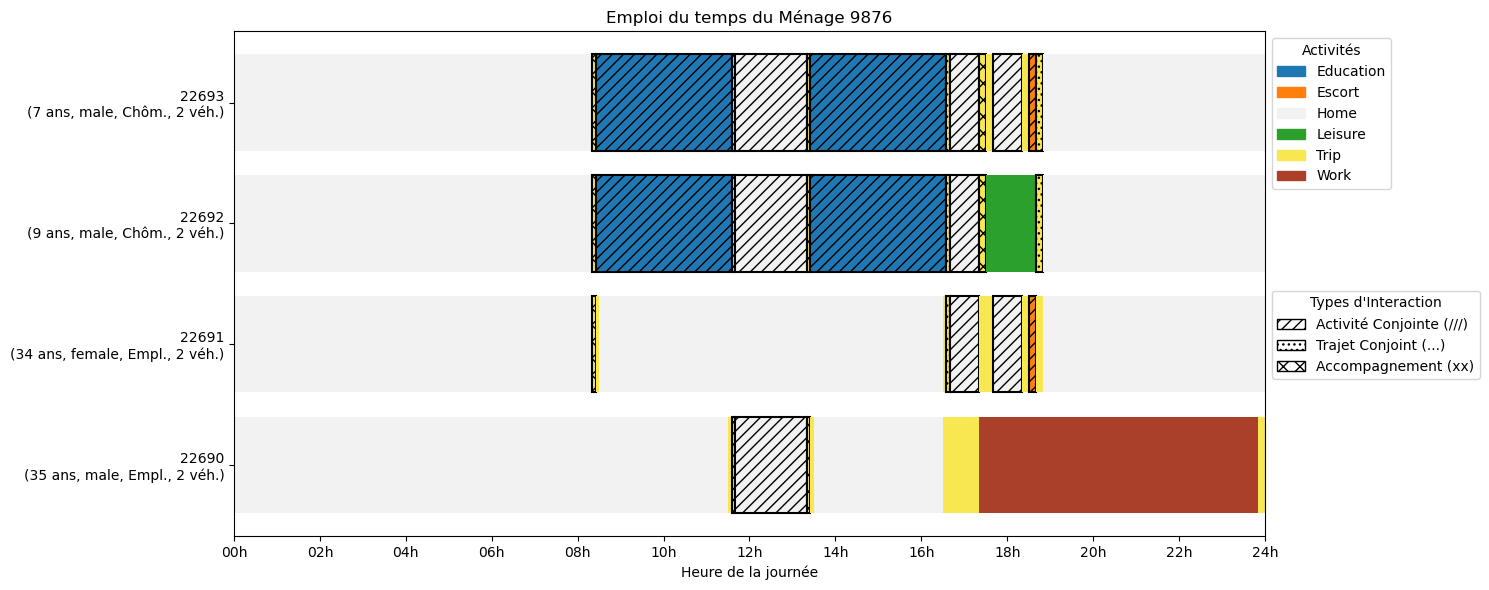

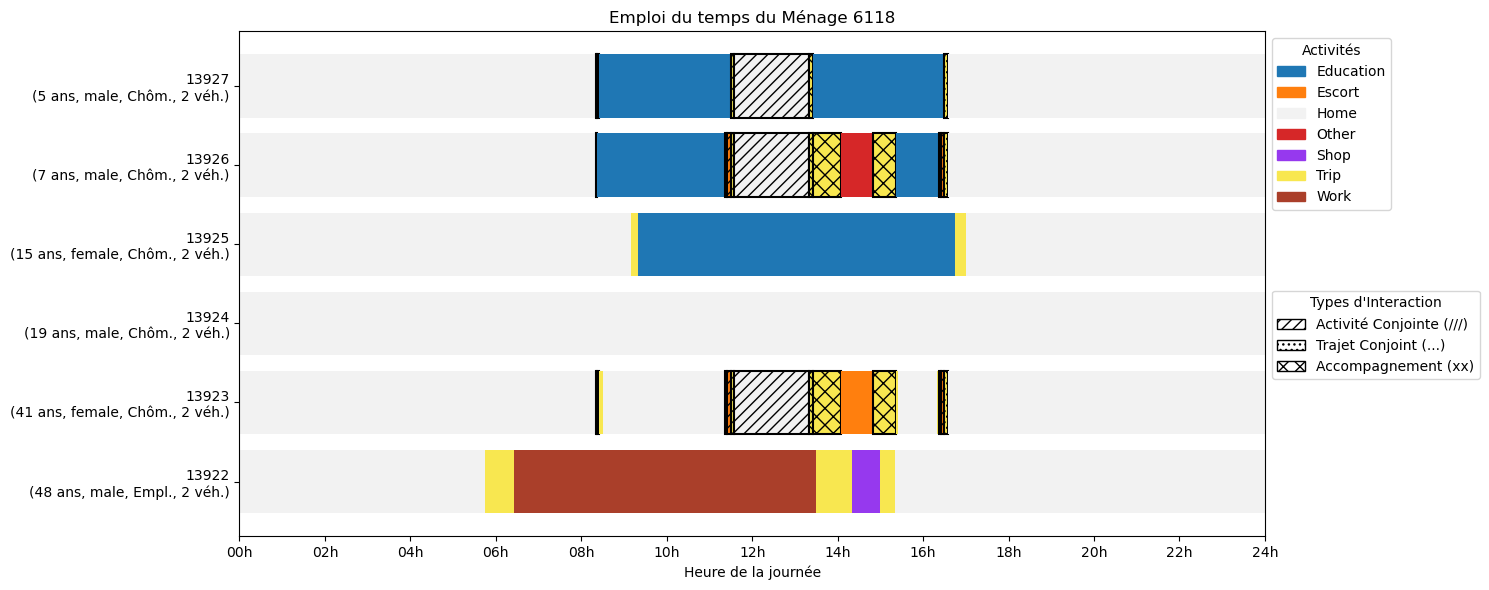

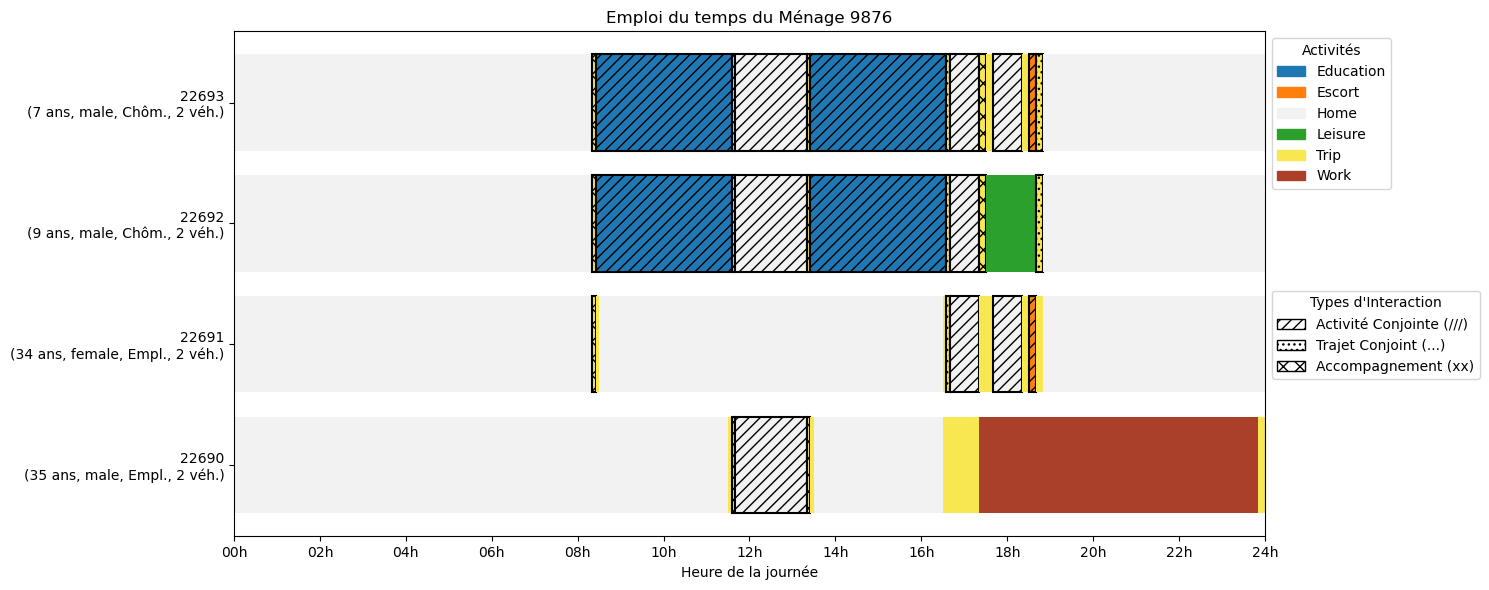

,schedule_id,pid,start_h,end_h,act,interaction_type
0,179793,22690,00:00,11:30,home,0
1,179794,22690,11:30,11:35,trip,0
2,179795,22690,11:35,11:40,trip,2
3,179796,22690,11:40,13:20,home,1
4,179797,22690,13:20,13:25,trip,3
5,179798,22690,13:25,13:30,trip,0
6,179799,22690,13:30,16:30,home,0
7,179800,22690,16:30,17:20,trip,0
8,179801,22690,17:20,23:50,work,0
9,179802,22690,23:50,24:00,trip,0


In [12]:
import pandas as pd
import numpy as np

def get_interactive_households_stats(df_interactions, df_schedules, df_attributes=None, min_interactions=1):
    # récupère hid dans interactions
    if 'hid' in df_schedules.columns:
        mapping = df_schedules[['schedule_id', 'hid']].drop_duplicates()
        df_merged = df_interactions.merge(mapping, on='schedule_id', how='left')
        
    elif df_attributes is not None:
        mapping = df_attributes[['pid', 'hid']].drop_duplicates()
        df_merged = df_interactions.merge(mapping, on='pid', how='left')
    # filtres sur les interactions
    df_active = df_merged[df_merged['interaction_type'] > 0].copy()


    # On groupe par HID et type pour compter les occurrences
    stats = df_active.groupby(['hid', 'interaction_type']).size().unstack(fill_value=0)
    type_map = {1: 'n_joint_act', 2: 'n_joint_trip', 3: 'n_escort'}
    stats.rename(columns=type_map, inplace=True)

    # total
    stats['total_interactions'] = stats.sum(axis=1)

    # + taille du ménage
    if df_attributes is not None:
        hh_sizes = df_attributes.groupby('hid')['pid'].nunique()
        stats['hh_size'] = stats.index.map(hh_sizes)

    # pour filtrer
    stats = stats[stats['total_interactions'] >= min_interactions]
    stats = stats.sort_values('total_interactions', ascending=False)

    return stats



def plot_top_household(df_stats, df_schedules, df_interactions, df_attributes, rank=0):

    target_hid = df_stats.index[rank]
    print(f"Visualization du ménage : {target_hid}")
    print(f"Détails interactions : \n{df_stats.iloc[rank]}")
    
    df_det = plot_household_interaction_gantt(
        hid=target_hid,
        df_schedules=df_schedules,
        df_interactions=df_interactions,
        df_attributes=df_attributes
    )
    return df_det

df_schedules = pd.read_csv("caveat_schedules.csv")
df_interactions = pd.read_csv("caveat_interactions.csv")
df_attributes = pd.read_csv("caveat_attributes.csv")
if 'hid' not in df_schedules.columns:
    df_schedules = df_schedules.merge(df_attributes[['pid', 'hid']], on='pid', how='left')

hh_stats = get_interactive_households_stats(
    df_interactions, 
    df_schedules, 
    df_attributes,
    min_interactions=1
)

print(f"Nombre de ménages avec interactions : {len(hh_stats)}")
print(hh_stats.head(10)) 


plot_top_household(hh_stats, df_schedules, df_interactions, df_attributes, rank=40)

top_escort_hids = hh_stats.sort_values('n_escort', ascending=False)
if not top_escort_hids.empty:
    hid_escort = top_escort_hids.index[0]
    plot_household_interaction_gantt(hid_escort, df_schedules, df_interactions, df_attributes)

    hid_escort = top_escort_hids.index[0]
trips_df = plot_household_interaction_gantt(9876, df_schedules, df_interactions, df_attributes)
display(trips_df.head(100))   # ou display(trips_df) en notebook


In [3]:
import pandas as pd
df_interactions = pd.read_csv("caveat_interactions.csv")
df_interactions

,schedule_id,interaction_type,pid
0,0,0,0
1,1,0,0
2,2,0,0
3,3,0,0
4,4,0,0
...,...,...,...
271046,271046,0,35173
271047,271047,0,35174
271048,271048,0,35174
271049,271049,0,35174


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

df_schedules = pd.read_csv('caveat_schedules.csv')
df_interactions = pd.read_csv('caveat_interactions.csv')
df_attributes = pd.read_csv('caveat_attributes.csv')

if 'hid' not in df_schedules.columns and {'pid', 'hid'}.issubset(df_attributes.columns):
    df_schedules = df_schedules.merge(df_attributes[['pid', 'hid']], on='pid', how='left')

for col in ['start', 'end']:
    if col in df_schedules.columns:
        df_schedules[col] = pd.to_numeric(df_schedules[col], errors='coerce')

for col in ['overlap_start', 'overlap_end']:
    if col in df_interactions.columns:
        df_interactions[col] = pd.to_numeric(df_interactions[col], errors='coerce')


In [2]:
def _prepare_overlap_interactions(df_schedules, df_interactions):
    # Join pour recuperer act/hid sur chaque ligne interaction
    cols = ['schedule_id', 'pid', 'act', 'hid', 'start', 'end']
    sched_meta = df_schedules[[c for c in cols if c in df_schedules.columns]].copy()

    dfi = df_interactions.copy()
    if 'interaction_bin' in dfi.columns:
        dfi = dfi[dfi['interaction_bin'].fillna(0).astype(int) > 0].copy()

    dfi = dfi.merge(sched_meta, on=['schedule_id', 'pid'], how='left')

    # interaction_type absent dans le nouveau format: on l'infere via act
    if 'interaction_type' not in dfi.columns:
        dfi['interaction_type'] = (dfi['act'].astype(str).str.lower() == 'trip').map({True: 2, False: 1}).astype(int)

    # Si overlap absent, fallback sur toute la ligne schedule
    if 'overlap_start' not in dfi.columns:
        dfi['overlap_start'] = dfi['start']
    if 'overlap_end' not in dfi.columns:
        dfi['overlap_end'] = dfi['end']

    # Exclure escort et 'other' (si other vient d'escort dans ton export)
    act_low = dfi['act'].astype(str).str.lower()
    dfi = dfi[~act_low.isin(['escort', 'other'])].copy()

    # Garder seulement les intervalles valides
    dfi = dfi[(dfi['overlap_start'].notna()) & (dfi['overlap_end'].notna())]
    dfi = dfi[dfi['overlap_end'] > dfi['overlap_start']].copy()

    return dfi

dfi_overlap = _prepare_overlap_interactions(df_schedules, df_interactions)
print('Interactions overlap-ready:', len(dfi_overlap))
display(dfi_overlap.head(10))


Interactions overlap-ready: 120856


,schedule_id,pid,interaction_bin,overlap_start,overlap_end,act,hid,start,end,interaction_type
0,20494,2383,1,1095.0,1440.0,home,1295,1095,1440,1
1,217836,28091,1,0.0,510.0,home,12017,0,530,1
2,199481,25423,1,0.0,300.0,home,10935,0,300,1
3,7110,774,1,0.0,470.0,home,452,0,480,1
5,141796,17907,1,1110.0,1440.0,home,7724,1110,1440,1
6,158609,20040,1,0.0,440.0,home,8681,0,440,1
7,187410,23735,1,1200.0,1440.0,home,10318,1035,1440,1
8,57226,7075,1,995.0,1440.0,home,3406,995,1440,1
9,28066,3280,1,1015.0,1440.0,home,1761,1015,1440,1
10,234793,30264,1,780.0,810.0,home,12961,780,810,1


In [3]:
def plot_household_joint_overlap_gantt(hid, df_schedules, dfi_overlap, df_attributes=None, figsize=(16, 6)):
    hh = df_schedules[df_schedules['hid'] == hid].copy()
    if hh.empty:
        print(f'No schedules for hid={hid}')
        return None

    # Meme logique de filtrage que demandee
    hh['act'] = hh['act'].astype(str)
    hh = hh[~hh['act'].str.lower().isin(['escort', 'other'])].copy()

    # Reutilise la colormap historique du notebook si elle existe
    if 'ACTIVITY_COLORS' in globals():
        act_colors = ACTIVITY_COLORS
    else:
        act_colors = {
            'home': '#f2f2f2', 'work': '#AA3F2A', 'shop': '#9639ee', 'education': '#1f77b4',
            'leisure': '#2ca02c', 'escort': '#ff7f0e', 'other': '#d62728', 'trip': '#f8e750', 'unknown': '#333333'
        }

    members = sorted(hh['pid'].dropna().astype(str).unique())
    pid_to_y = {pid: i for i, pid in enumerate(members)}

    fig, ax = plt.subplots(figsize=figsize)

    present_acts = set()

    # 1) Barres de base
    for _, r in hh.sort_values(['pid', 'start']).iterrows():
        pid = str(r['pid'])
        y = pid_to_y[pid]
        start = float(r['start'])
        end = float(r['end'])
        width = max(0.0, end - start)
        if width <= 0:
            continue
        act_key = str(r['act']).lower().strip()
        present_acts.add(act_key)
        color = act_colors.get(act_key, act_colors.get('unknown', '#333333'))
        ax.barh(y=y, width=width, left=start, height=0.8, color=color, edgecolor='white')

    # 2) Overlays interactions (uniquement sur overlap)
    hh_i = dfi_overlap[dfi_overlap['hid'] == hid].copy()
    style = {
        1: {'hatch': '///', 'edgecolor': 'black', 'label': 'Activite conjointe (overlap)'},
        2: {'hatch': '...', 'edgecolor': 'black', 'label': 'Trajet conjoint'}
    }

    for _, r in hh_i.iterrows():
        pid = str(r['pid'])
        if pid not in pid_to_y:
            continue
        y = pid_to_y[pid]
        s = float(r['overlap_start'])
        e = float(r['overlap_end'])
        w = max(0.0, e - s)
        if w <= 0:
            continue
        it = int(r['interaction_type']) if pd.notna(r['interaction_type']) else 1
        st = style.get(it, style[1])
        ax.barh(
            y=y, width=w, left=s, height=0.8,
            facecolor='none', edgecolor=st['edgecolor'], hatch=st['hatch'], linewidth=1.3
        )

    # Labels membres + attributs (meme style que la premiere cellule)
    y_labels = []
    for pid in members:
        label = f'PID: {pid}'
        if df_attributes is not None:
            attr = df_attributes[df_attributes['pid'].astype(str) == pid]
            if not attr.empty:
                age = attr.iloc[0].get('age', '?')
                sex = attr.iloc[0].get('sex', '?')
                employed = attr.iloc[0].get('employed', '?')
                vehicles = attr.iloc[0].get('number_of_vehicles', '?')
                emp_txt = 'Empl.' if bool(employed) else 'Chom.'
                label = f"{pid}\n({age} ans, {sex}, {emp_txt}, {vehicles} veh.)"
        y_labels.append(label)

    ax.set_yticks(list(pid_to_y.values()))
    ax.set_yticklabels(y_labels)

    ax.set_xlim(0, 1440)
    ax.set_xticks(np.arange(0, 1441, 120))
    ax.set_xticklabels([f"{int(h//60):02d}h" for h in np.arange(0, 1441, 120)])
    ax.set_xlabel('Heure de la journee')
    ax.set_ylabel('Membres')
    ax.set_title(f'Menage {hid}: trips/activites joints (overlap, sans escort)')
    ax.grid(axis='x', linestyle='--', alpha=0.3)

    sorted_acts = sorted(list(present_acts))
    leg_act = [
        mpatches.Patch(color=act_colors.get(a, act_colors.get('unknown', '#333333')), label=a.capitalize())
        for a in sorted_acts
    ]
    leg_int = [
        mpatches.Patch(facecolor='white', edgecolor=v['edgecolor'], hatch=v['hatch'], label=v['label'])
        for v in style.values()
    ]

    legend1 = ax.legend(handles=leg_act, title='Activites', loc='upper left', bbox_to_anchor=(1, 1))
    if leg_int:
        ax.legend(handles=leg_int, title="Types d'interaction", loc='upper left', bbox_to_anchor=(1, 0.5))
        ax.add_artist(legend1)

    plt.tight_layout()
    plt.show()

    cols = ['schedule_id', 'pid', 'act', 'interaction_type', 'overlap_start', 'overlap_end']
    keep = [c for c in cols if c in hh_i.columns]
    return hh_i[keep].sort_values(['pid', 'overlap_start'])


Households with joint overlaps: 8606


hid
12946    131
14040    119
3060     116
3747     113
4913     111
7458     108
1511     100
12313     95
10726     94
452       89
dtype: int64

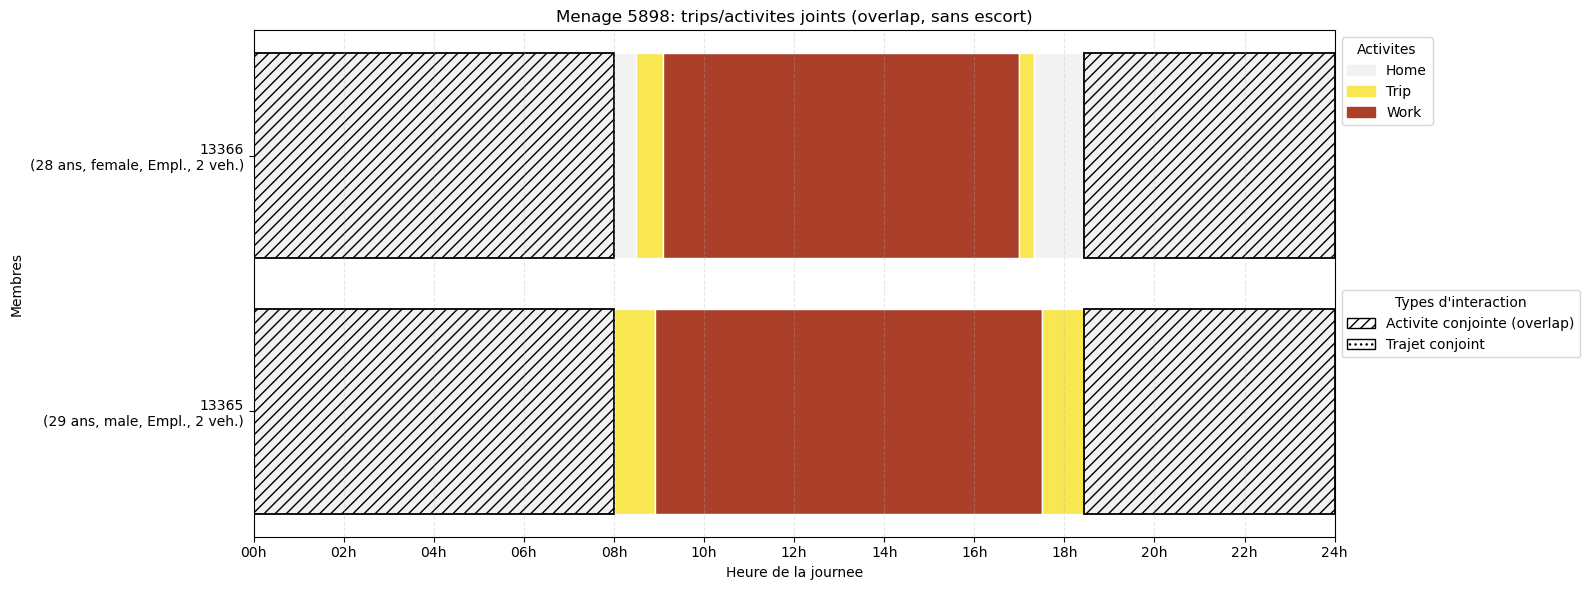

,schedule_id,pid,act,interaction_type,overlap_start,overlap_end
83898,106016,13365,home,1,0.0,480.0
119797,106020,13365,home,1,1106.0,1440.0
41482,106021,13366,home,1,0.0,480.0
83792,106025,13366,home,1,1106.0,1440.0


In [6]:
import numpy as np
# Menages avec interactions jointes (activities/trips), escort deja retire
hid_counts = dfi_overlap.groupby('hid').size().sort_values(ascending=False)
print('Households with joint overlaps:', len(hid_counts))
display(hid_counts.head(10))

# Exemple: top menage
if len(hid_counts) > 0:
    hid0 = int(hid_counts.index[8200])
    out = plot_household_joint_overlap_gantt(hid0, df_schedules, dfi_overlap, df_attributes=df_attributes)
    display(out.head(50))


In [5]:
import pandas as pd
sch = pd.read_csv("caveat_schedules.csv")
sch[sch['pid'] <= 20].to_csv("subset_schedules_ref.csv")

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

df_schedules = pd.read_csv('caveat_schedules.csv')
df_interactions = pd.read_csv('caveat_interactions.csv')
df_attributes = pd.read_csv('caveat_attributes.csv')

df_schedules.groupby("pid").count()

,schedule_id,act,start,end
pid,,,,
0,9,9,9,9
1,11,11,11,11
2,22,22,22,22
3,9,9,9,9
4,9,9,9,9
...,...,...,...,...
35170,17,17,17,17
35171,13,13,13,13
35172,8,8,8,8
